In [16]:
! pip install -q numpy pandas matplotlib scikit-learn ISLP statsmodels

## Question 3

Suppose we fit a curve with basis functions $b_1(X)=X$, $b_2(X)=(X-1)^2 I(X\geq 1)$. (Note that $I(X\geq 1)$ equals 1 for $X\geq 1$ and 0 otherwise.) We fit the linear regression model

$$
Y=\beta_0+\beta_1b_1(X)+\beta_2b_2(X)+\epsilon,
$$

and obtain coefficient estimates $\hat{\beta}_0=1$, $\hat{\beta}_1=1$, $\hat{\beta}_2=-2$. Sketch the estimated curve between $X=-2$ and $X=2$. Note the intercepts, slopes, and other relevant information.


### 解答

將 $\hat\beta_0=1$、$\hat\beta_1=1$、$\hat\beta_2=-2$ 代入模型，可得

$$
\hat Y
=1+X-2(X-1)^2I(X\geq1)
=
\begin{cases}
1+X, & -2\leq X<1,\\[4pt]
1+X-2(X-1)^2, & 1\leq X\leq2.
\end{cases}
$$

因此，$X<1$ 的部分是一條斜率為 $1$ 的直線，從
$(-2,-1)$ 經過 $(-1,0)$、$(0,1)$，到達 $(1,2)$。
所以圖中與 $X$ 軸的交點是 $(-1,0)$，與 $Y$ 軸的交點是 $(0,1)$。

當 $X\geq1$ 時，

$$
\hat Y=1+X-2(X-1)^2=-2X^2+5X-1,
$$

二階導數為負，且一階導數在 $X=1$ 時為

$$
\frac{d\hat Y}{dX}=5-4X=1,
$$

所以是一段開口向下的拋物線。斜率與左側一致，且右側曲線仍通過 $(1,2)$，因此兩段曲線在 $X=1$ 平順接合，沒有跳躍或尖角。

拋物線的斜率由 $1$ 逐漸下降，在 $X=5/4$ 時變成 $0$。此時曲線達到最高點

$$
\left(\frac54,\frac{17}{8}\right)=(1.25,2.125).
$$

之後曲線下降，到 $X=2$ 時通過 $(2,1)$，斜率為 $-3$。

從圖中可知，函數從 $(-2,-1)$ 到 $(1,2)$ 的上升直線；接著從 $(1,2)$ 平順接上一段開口向下的拋物線，經過最高點 $(1.25,2.125)$，最後下降至 $(2,1)$。

**這個函數解決了非線性預測問題，一般的線性迴歸對參數 $\beta$ 是線性關係，而 Basis Functions 可以讓模型呈現非線性關係且本身函數連續也有蠻好的數學性質**

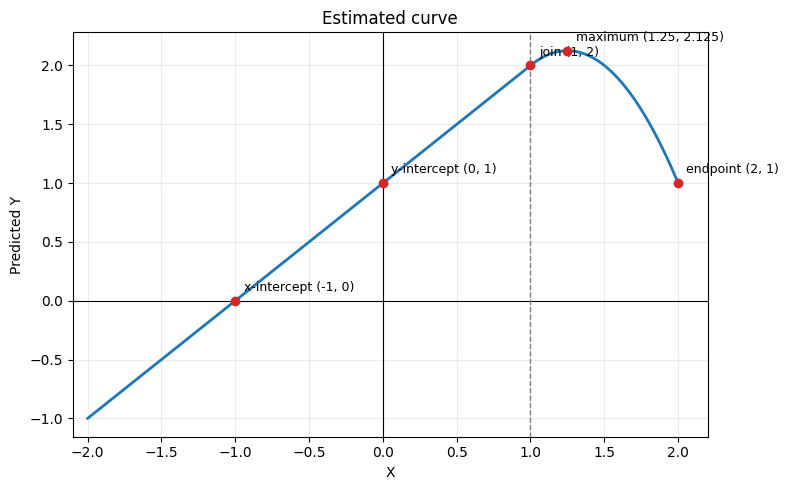

In [17]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-2, 2, 500)
y_hat = 1 + x - 2 * (x - 1)**2 * (x >= 1)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x, y_hat, color="tab:blue", linewidth=2)

points = {
    "x-intercept (-1, 0)": (-1, 0),
    "y-intercept (0, 1)": (0, 1),
    "join (1, 2)": (1, 2),
    "maximum (1.25, 2.125)": (1.25, 2.125),
    "endpoint (2, 1)": (2, 1),
}

for label, (px, py) in points.items():
    ax.scatter(px, py, color="tab:red", zorder=3)
    ax.annotate(
        label, (px, py), xytext=(6, 7),
        textcoords="offset points", fontsize=9
    )

ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.8)
ax.axvline(1, color="gray", linestyle="--", linewidth=1)

ax.set(
    xlim=(-2.1, 2.2),
    xlabel="X",
    ylabel="Predicted Y",
    title="Estimated curve",
)
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

## Question 9

This question uses the variables `dis` (the weighted mean of distances to five Boston employment centers) and `nox` (nitrogen oxides concentration in parts per 10 million) from the `Boston` data. We will treat `dis` as the predictor and `nox` as the response.

**(a)** Use the `poly()` function from the `ISLP.models` module to fit a cubic polynomial regression to predict `nox` using `dis`. Report the regression output, and plot the resulting data and polynomial fits.

**(b)** Plot the polynomial fits for a range of different polynomial degrees (say, from 1 to 10), and report the associated residual sum of squares.

**(c)** Perform cross-validation or another approach to select the optimal degree of the polynomial, and explain your results.

**(d)** Use the `bs()` function from the `ISLP.models` module to fit a regression spline to predict `nox` using `dis`. Report the output for the fit using four degrees of freedom. How did you choose the knots? Plot the resulting fit.

**(e)** Now fit a regression spline for a range of degrees of freedom, and plot the resulting fits and report the resulting RSS. Describe the results obtained.

**(f)** Perform cross-validation or another approach in order to select the best degrees of freedom for a regression spline on this data. Describe your results.


In [18]:
import pandas as pd
import statsmodels.api as sm
from copy import deepcopy
from ISLP import load_data
from ISLP.models import ModelSpec, poly, bs
from sklearn.model_selection import KFold

Boston = load_data("Boston")
data9 = Boston[["dis", "nox"]].copy()

# 固定 10 折
cv9 = KFold(
    n_splits=10,
    shuffle=True,
    random_state=20261108,
)

dis_grid9 = pd.DataFrame({
    "dis": np.linspace(
        data9["dis"].min(),
        data9["dis"].max(),
        400,
    )
})


def fit_ols9(data, term):
    """在指定資料上建立基底並配適含截距的 OLS。"""
    spec = ModelSpec([term]).fit(data)
    design = spec.transform(data)
    model = sm.OLS(data["nox"], design).fit()
    return spec, model


def predict_on_grid9(spec, model):
    return np.asarray(
        model.predict(spec.transform(dis_grid9))
    )


def cv_mse9(term):
    """每一折都只用該折訓練資料建立基底及配適模型。"""
    squared_errors = []

    for train_index, test_index in cv9.split(data9):
        train = data9.iloc[train_index]
        test = data9.iloc[test_index]

        spec, model = fit_ols9(train, deepcopy(term))
        predictions = np.asarray(
            model.predict(spec.transform(test))
        )

        squared_errors.extend(
            (test["nox"].to_numpy() - predictions) ** 2
        )

    return np.mean(squared_errors)

### (a) 解答

使用 `poly("dis", degree=3)` 建立

$$
\widehat{\mathrm{nox}} = \beta_0 + \beta_1\mathrm{dis} + \beta_2\mathrm{dis}^2 + \beta_3\mathrm{dis}^3
$$

這個模型訓練資料殘差平方和為

$$
\operatorname{RSS}\approx1.934107,
$$

而 $R^2\approx0.7148$。相較於直線模型的 RSS 約 2.768563，三次曲線能更充分描述 `dis` 與 `nox` 之間的彎曲關係。

散點與配適曲線顯示：`dis` 較小的地區通常有較高的 `nox`；隨著 `dis` 增加，`nox` 先明顯下降，之後下降趨緩。

**`poly()` 預設建立的是經過轉換的多項式基底，所以迴歸輸出中的三個係數不是原始 $dis$、$dis^2$、$dis^3$ 的係數，不過雖然係數表示不同，但配適曲線相同。此外，增加多項式次數通常能降低訓練 RSS，卻不代表能改善模型的泛化能力。**

                            OLS Regression Results                            
Dep. Variable:                    nox   R-squared:                       0.715
Model:                            OLS   Adj. R-squared:                  0.713
Method:                 Least Squares   F-statistic:                     419.3
Date:                Mon, 09 Nov 2026   Prob (F-statistic):          2.71e-136
Time:                        19:02:46   Log-Likelihood:                 690.44
No. Observations:                 506   AIC:                            -1373.
Df Residuals:                     502   BIC:                            -1356.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
intercept                  0

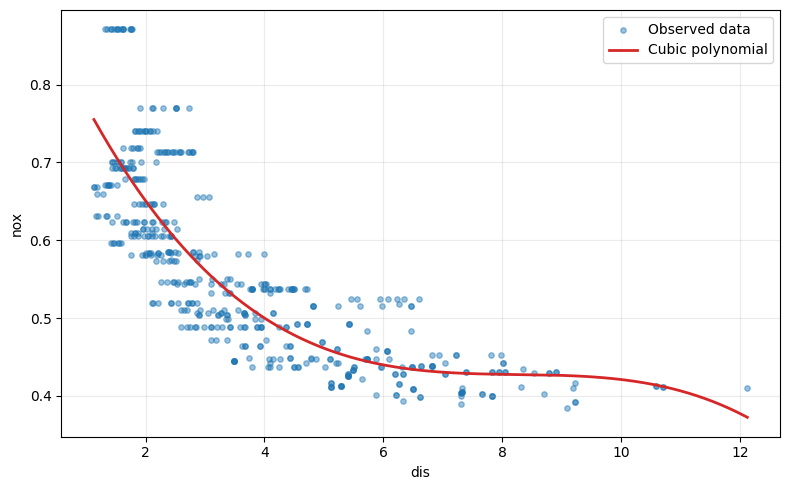

In [19]:
cubic_spec9, cubic_model9 = fit_ols9(
    data9,
    poly("dis", degree=3),
)

print(cubic_model9.summary())

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    data9["dis"],
    data9["nox"],
    s=15,
    alpha=0.45,
    label="Observed data",
)
ax.plot(
    dis_grid9["dis"],
    predict_on_grid9(cubic_spec9, cubic_model9),
    color="tab:red",
    linewidth=2,
    label="Cubic polynomial",
)

ax.set(xlabel="dis", ylabel="nox")
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()
plt.show()

### (b) 解答

分別配適 1 至 10 次多項式，並計算各模型在原資料上的殘差平方和（RSS）。

| 次數 | RSS |
|---:|---:|
| 1 | 2.768563 |
| 2 | 2.035262 |
| 3 | 1.934107 |
| 4 | 1.932981 |
| 5 | 1.915290 |
| 6 | 1.878257 |
| 7 | 1.849484 |
| 8 | 1.835630 |
| 9 | 1.833331 |
| 10 | 1.832171 |

理論上次數提高時，訓練資料的 RSS 會持續下降，因為如果多次方程式高次係數為零就會降下來次方數，某種程度來說低次方函數算是高次方的子集合，所以 RSS 通常會隨著次方提高而下降，但一直增加次方數一定會碰到過擬合問題，以這題來說從三次增加到十次，RSS 只由約 1.934 降至 1.832；較低的訓練 RSS 本身不能證明高次模型對新資料預測得更好，因為會有過擬合問題。

 Degree      RSS
      1 2.768563
      2 2.035262
      3 1.934107
      4 1.932981
      5 1.915290
      6 1.878257
      7 1.849484
      8 1.835630
      9 1.833331
     10 1.832171


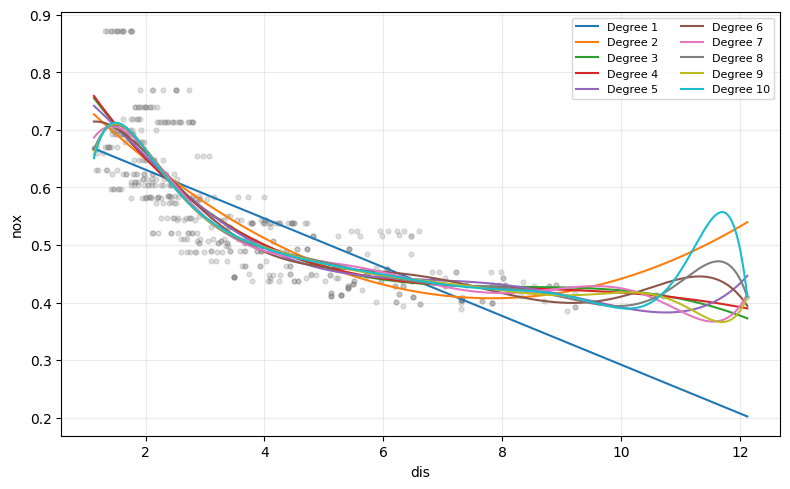

In [20]:
poly_rows9 = []
poly_fits9 = {}

for degree in range(1, 11):
    spec, model = fit_ols9(
        data9,
        poly("dis", degree=degree),
    )

    poly_fits9[degree] = (spec, model)
    poly_rows9.append({
        "Degree": degree,
        "RSS": model.ssr,
    })

poly_results9 = pd.DataFrame(poly_rows9)

print(
    poly_results9.to_string(
        index=False,
        formatters={"RSS": "{:.6f}".format},
    )
)

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    data9["dis"],
    data9["nox"],
    s=12,
    alpha=0.25,
    color="gray",
)

for degree in range(1, 11):
    spec, model = poly_fits9[degree]
    ax.plot(
        dis_grid9["dis"],
        predict_on_grid9(spec, model),
        linewidth=1.5,
        label=f"Degree {degree}",
    )

ax.set(xlabel="dis", ylabel="nox")
ax.legend(ncol=2, fontsize=8)
ax.grid(alpha=0.25)

fig.tight_layout()
plt.show()

### (c) 解答

這小題就是為了解決 (b) 的過擬合問題，我們使用十折交叉驗證比較 1 至 10 次多項式，並以平均驗證 MSE 最小作為選擇準則。每一折的 `poly()` 基底只根據該折的訓練資料建立。

本次最小的交叉驗證 MSE 約為

$$
\boxed{\operatorname{CV\ MSE}=0.003865},
$$

對應

$$
\boxed{\text{三次多項式}}.
$$

二次、三次、四次模型的 CV MSE 分別約為 0.004066、0.003865、0.003870。三次與四次非常接近，但四次模型沒有帶來更低的驗證誤差，因此選擇三次。

這也說明 (b) 中持續下降的訓練 RSS 不能用來決定最佳次數。較高次的曲線雖可更貼合原資料，對未參與配適的資料卻可能沒有改善；部分高次模型的驗證誤差甚至明顯增加。

   Degree    CV MSE
0       1  0.005519
1       2  0.004066
2       3  0.003865
3       4  0.003870
4       5  0.004159
5       6  0.005343
6       7  0.012553
7       8  0.012603
8       9  0.014473
9      10  0.003908

最佳多項式次數：3


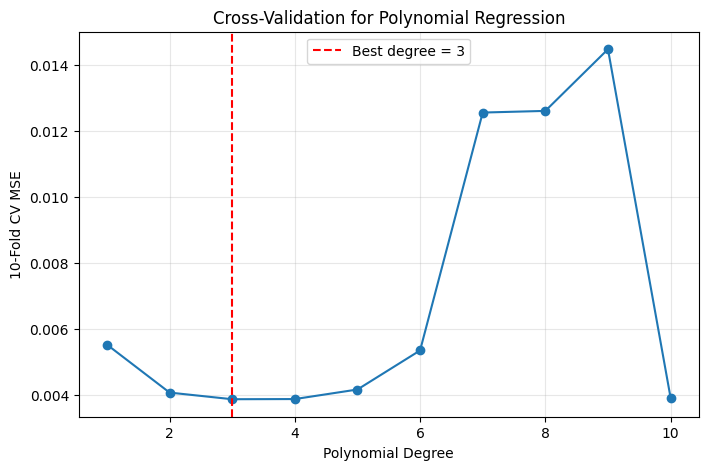

In [21]:
# 10-Fold Cross-Validation：比較 1～10 次多項式
poly_cv9 = pd.DataFrame({
    "Degree": range(1, 11),
    "CV MSE": [
        cv_mse9(poly("dis", degree=d))
        for d in range(1, 11)
    ],
})

# 找出 CV MSE 最小的次數
best_degree9 = int(
    poly_cv9.loc[
        poly_cv9["CV MSE"].idxmin(),
        "Degree"
    ]
)

print(poly_cv9)
print(f"\n最佳多項式次數：{best_degree9}")

# 繪製 CV MSE
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    poly_cv9["Degree"],
    poly_cv9["CV MSE"],
    marker="o"
)

ax.axvline(
    best_degree9,
    color="red",
    linestyle="--",
    label=f"Best degree = {best_degree9}"
)

ax.set(
    xlabel="Polynomial Degree",
    ylabel="10-Fold CV MSE",
    title="Cross-Validation for Polynomial Regression"
)

ax.legend()
ax.grid(alpha=0.3)

plt.show()

### (d) 四個自由度的迴歸樣條

使用 `bs("dis", df=4, degree=3)` 建立三次 B-spline 基底，再配適含截距的迴歸模型。而結果為

$$
\operatorname{RSS}\approx1.922775,
\qquad
R^2\approx0.7164.
$$

`df=4` 對應四個樣條基底函數；對三次樣條而言，這項設定有一個內部節點。讓 `bs()` 根據訓練資料自動選擇節點位置，約在 `dis` 的中位數附近；完整資料的中位數約為 3.20745。

選在資料較密集的中間位置，能讓曲線在主要觀測區域改變形狀，同時維持節點處的平順銜接。配適圖同樣顯示 `dis` 增加時，`nox` 整體下降，且下降幅度並不固定。

迴歸表中的係數屬於各個 B-spline 基底，不能直接解讀成 `dis` 每增加一單位時 `nox` 固定改變多少。

                            OLS Regression Results                            
Dep. Variable:                    nox   R-squared:                       0.716
Model:                            OLS   Adj. R-squared:                  0.714
Method:                 Least Squares   F-statistic:                     316.5
Date:                Mon, 09 Nov 2026   Prob (F-statistic):          1.39e-135
Time:                        19:02:47   Log-Likelihood:                 691.93
No. Observations:                 506   AIC:                            -1374.
Df Residuals:                     501   BIC:                            -1353.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
intercept           

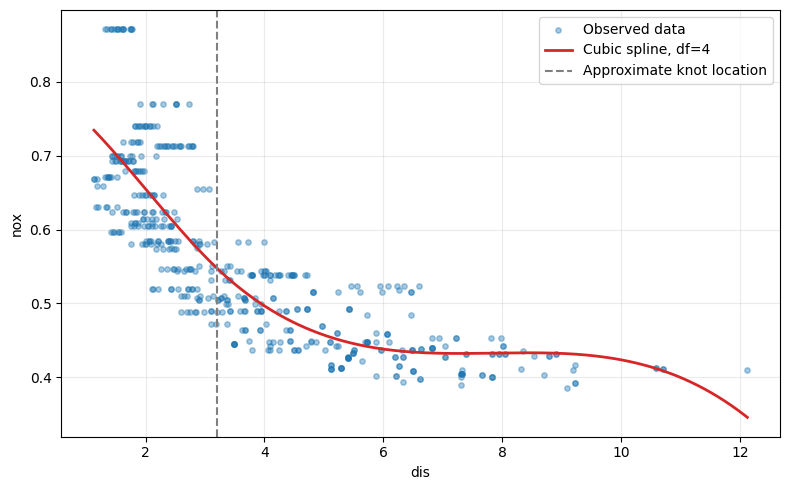

In [22]:
spline4_spec9, spline4_model9 = fit_ols9(
    data9,
    bs("dis", df=4, degree=3),
)

print(spline4_model9.summary())
print(f"\nRSS：{spline4_model9.ssr:.6f}")
print(f"dis 中位數：{data9['dis'].median():.5f}")

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    data9["dis"],
    data9["nox"],
    s=15,
    alpha=0.4,
    label="Observed data",
)
ax.plot(
    dis_grid9["dis"],
    predict_on_grid9(spline4_spec9, spline4_model9),
    color="tab:red",
    linewidth=2,
    label="Cubic spline, df=4",
)
ax.axvline(
    data9["dis"].median(),
    color="gray",
    linestyle="--",
    label="Approximate knot location",
)

ax.set(xlabel="dis", ylabel="nox")
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()
plt.show()

### (e) 不同自由度的迴歸樣條

以三次 B-spline 分別配適自由度 4 至 10 的模型：

| 自由度 | RSS |
|---:|---:|
| 4 | 1.922775 |
| 5 | 1.840173 |
| 6 | 1.833966 |
| 7 | 1.829884 |
| 8 | 1.816995 |
| 9 | 1.825653 |
| 10 | 1.792535 |

自由度增加後，曲線通常能呈現更多局部變化，RSS 整體呈下降趨勢。不過，從自由度 8 增至 9 時，RSS 由約 1.817 升至 1.826。

因為這裡每次都讓 `bs()` 依自由度重新安排節點；不同自由度的樣條空間不一定互相包含，因此 RSS 不保證逐項下降。這與依序加入更高次項、模型彼此包含的多項式迴歸不同。

自由度 10 的訓練 RSS 最低，但這仍不足以選定它作為預測模型，需要檢查交叉驗證誤差。

 df      RSS
  4 1.922775
  5 1.840173
  6 1.833966
  7 1.829884
  8 1.816995
  9 1.825653
 10 1.792535


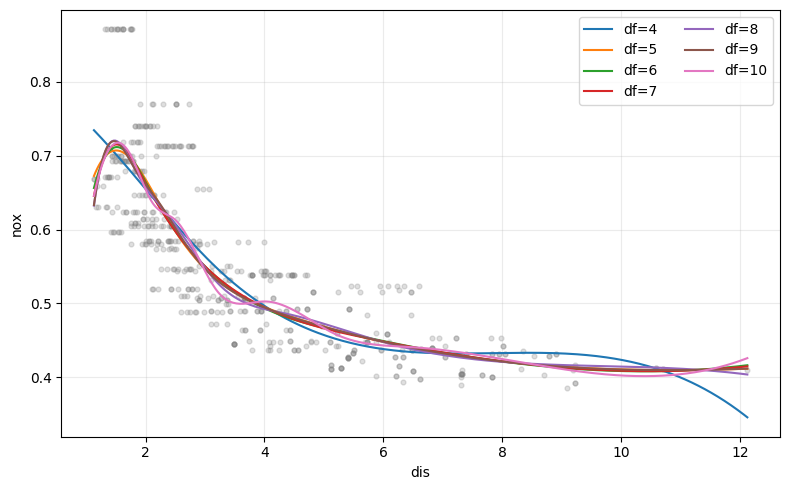

In [25]:
spline_rows9 = []
spline_fits9 = {}

for df in range(4, 11):
    spec, model = fit_ols9(
        data9,
        bs("dis", df=df, degree=3),
    )

    spline_fits9[df] = (spec, model)
    spline_rows9.append({
        "df": df,
        "RSS": model.ssr,
    })

spline_results9 = pd.DataFrame(spline_rows9)

print(
    spline_results9.to_string(
        index=False,
        formatters={"RSS": "{:.6f}".format},
    )
)

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    data9["dis"],
    data9["nox"],
    s=12,
    alpha=0.25,
    color="gray",
)

for df in range(4, 11):
    spec, model = spline_fits9[df]
    ax.plot(
        dis_grid9["dis"],
        predict_on_grid9(spec, model),
        linewidth=1.5,
        label=f"df={df}",
    )

ax.set(xlabel="dis", ylabel="nox")
ax.legend(ncol=2)
ax.grid(alpha=0.25)

fig.tight_layout()
plt.show()

### (f) 解答

使用相同的十折分組，比較自由度 4 至 10 的三次 B-spline，並以平均驗證 MSE 最小作為準則。每一折都只使用該折的訓練資料估計節點與迴歸係數。

本次結果如下：

| 自由度 | 十折 CV MSE |
|---:|---:|
| 4 | 0.003873 |
| 5 | 0.003687 |
| 6 | 0.003681 |
| 7 | 0.003680 |
| 8 | 0.003669 |
| 9 | 0.003693 |
| 10 | 0.003659 |

在本次比較的候選範圍內，最小值為

$$
\boxed{\operatorname{CV\ MSE}\approx0.003659},
\qquad
\boxed{\text{自由度}=10}.
$$

但 10 是目前搜尋範圍的上界，所以這個結果只表示「在自由度 4 至 10 當中，10 最好」，不能據此斷言超過 10 的自由度一定較差。

另外，自由度 5 至 10 的 CV MSE 都相當接近；例如自由度 8 與 10 分別約為 0.003669、0.003659。因此，若希望曲線較簡單，自由度 8 也是值得考慮的選擇。

 df   CV MSE
  4 0.003873
  5 0.003687
  6 0.003681
  7 0.003680
  8 0.003669
  9 0.003693
 10 0.003659

在候選範圍內選出的自由度：10


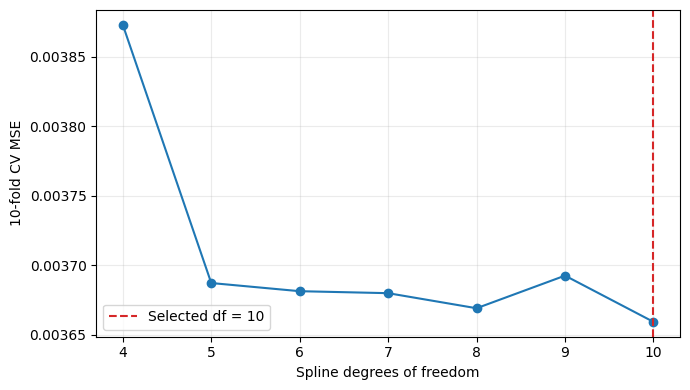

In [26]:
spline_cv9 = pd.DataFrame({
    "df": range(4, 11),
    "CV MSE": [
        cv_mse9(bs("dis", df=df, degree=3))
        for df in range(4, 11)
    ],
})

best_df9 = int(
    spline_cv9.loc[
        spline_cv9["CV MSE"].idxmin(),
        "df",
    ]
)

print(
    spline_cv9.to_string(
        index=False,
        formatters={"CV MSE": "{:.6f}".format},
    )
)
print(f"\n在候選範圍內選出的自由度：{best_df9}")

fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    spline_cv9["df"],
    spline_cv9["CV MSE"],
    marker="o",
)
ax.axvline(
    best_df9,
    color="tab:red",
    linestyle="--",
    label=f"Selected df = {best_df9}",
)

ax.set(
    xlabel="Spline degrees of freedom",
    ylabel="10-fold CV MSE",
)
ax.set_xticks(range(4, 11))
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()
plt.show()

## Question 10

This question relates to the `College` data set.

**(a)** Split the data into a training set and a test set. Using out-of-state tuition as the response and the other variables as the predictors, perform forward stepwise selection on the training set in order to identify a satisfactory model that uses just a subset of the predictors.

**(b)** Fit a GAM on the training data, using out-of-state tuition as the response and the features selected in the previous step as the predictors. Plot the results, and explain your findings.

**(c)** Evaluate the model obtained on the test set, and explain the results obtained.

**(d)** For which variables, if any, is there evidence of a non-linear relationship with the response?


### (a) 解答

使用 Forward Stepwise Selection，以 **BIC 最小**作為變數選擇準則：

$$
BIC=-2\log(L)+k\log(n)
$$

本題將 `College` 資料集分成 80% Training Set 與 20% Test Set，以 `Outstate` 為應變數，其餘變數為解釋變數。因此分成 621 筆 Training Data 與 156 筆 Test Data，依序選出以下六個變數：

| 順序 | Selected Variable | BIC |
|---:|---|---:|
| 1 | Expend | 11707.356 |
| 2 | Private_Yes | 11521.263 |
| 3 | Room.Board | 11383.196 |
| 4 | perc.alumni | 11316.035 |
| 5 | PhD | 11283.911 |
| 6 | Grad.Rate | 11269.530 |

最終模型結果：

$$
\boxed{BIC=11269.530}
$$

$$
\boxed{R^2=0.7429}
$$

FSS 最終選出 6 個變數，模型能解釋約 74.29% 的訓練資料變異，且加入其他變數已無法繼續降低 BIC。

In [29]:
from sklearn.model_selection import train_test_split

# 1. 載入資料
College = load_data("College")

X10 = College.drop(columns=["Outstate"])
y10 = College["Outstate"]

# 類別變數轉為 Dummy Variables
X10 = pd.get_dummies(X10, drop_first=True, dtype=float)

# 2. 分割 Training / Test Set
X_train10, X_test10, y_train10, y_test10 = train_test_split(
    X10, y10,
    test_size=0.2,
    random_state=42
)

# 3. Forward Stepwise Selection
selected10 = []
remaining10 = list(X_train10.columns)

# 建立只有截距的模型
null_X10 = pd.DataFrame(
    {"const": 1.0},
    index=X_train10.index
)

best_bic10 = sm.OLS(y_train10, null_X10).fit().bic

history10 = []

while remaining10:
    candidates = []

    for feature in remaining10:
        features = selected10 + [feature]

        X_fit = sm.add_constant(
            X_train10[features],
            has_constant="add"
        )

        model = sm.OLS(y_train10, X_fit).fit()
        candidates.append((model.bic, feature))

    # 選擇 BIC 最低的變數
    new_bic, best_feature = min(candidates)

    # 如果 BIC 沒有改善，就停止
    if new_bic >= best_bic10:
        break

    selected10.append(best_feature)
    remaining10.remove(best_feature)
    best_bic10 = new_bic

    history10.append({
        "Step": len(selected10),
        "Variable": best_feature,
        "BIC": best_bic10
    })

# 4. 最終模型
X_selected10 = sm.add_constant(
    X_train10[selected10],
    has_constant="add"
)

final_model10 = sm.OLS(
    y_train10, X_selected10
).fit()

# 5. 輸出結果
print("Selected Variables:", selected10)
print("Number of Variables:", len(selected10))
print("\nSelection History:")
print(pd.DataFrame(history10))

print("\nFinal Model Summary:")
print(final_model10.summary())

Selected Variables: ['Expend', 'Private_Yes', 'Room.Board', 'perc.alumni', 'PhD', 'Grad.Rate']
Number of Variables: 6

Selection History:
   Step     Variable           BIC
0     1       Expend  11707.356455
1     2  Private_Yes  11521.262536
2     3   Room.Board  11383.195912
3     4  perc.alumni  11316.035087
4     5          PhD  11283.911071
5     6    Grad.Rate  11269.530271

Final Model Summary:
                            OLS Regression Results                            
Dep. Variable:               Outstate   R-squared:                       0.743
Model:                            OLS   Adj. R-squared:                  0.740
Method:                 Least Squares   F-statistic:                     295.7
Date:                Mon, 09 Nov 2026   Prob (F-statistic):          2.06e-177
Time:                        19:43:47   Log-Likelihood:                -5612.3
No. Observations:                 621   AIC:                         1.124e+04
Df Residuals:                     614   BI

### (b) 解釋

使用 (a) 選出的六個變數建立 GAM，對五個連續變數使用 Natural Cubic Splines（$df=4$），並將 `Private_Yes` 保留為線性項：


$$
\begin{aligned}
\widehat{\mathrm{Outstate}}
={}&\beta_0+f_1(\mathrm{Expend})
&+f_2(\mathrm{Room.Board})
&+f_3(\mathrm{perc.alumni})
&+f_4(\mathrm{PhD})
&+f_5(\mathrm{Grad.Rate})
&+\gamma\,\mathrm{Private\_Yes}
\end{aligned}
$$

本次訓練結果：

$$
\boxed{R^2\approx0.7863}
$$

$$
\boxed{MSE\approx3{,}443{,}912}
$$

GAM 的訓練 $R^2$ 由線性模型的 $0.7429$ 提升至 $0.7863$，表示允許非線性關係後，模型能解釋更多訓練資料的變異。此外，控制其他變數後，私立大學的預測學費平均約高出 2,534 美元。

GAM 透過 Spline 描述各變數的非線性效果，但訓練 $R^2$ 較高不代表測試資料的預測能力一定較好。

而 GAM 的 Partial Effect 圖可以觀察到各變數與 `Outstate` 的關係不完全呈線性，尤其是 `phd` 以及 `grad.rate` ，而 GAM 能捕捉這些非線性變化。

Training R²: 0.7863
Training MSE: 3444684.67


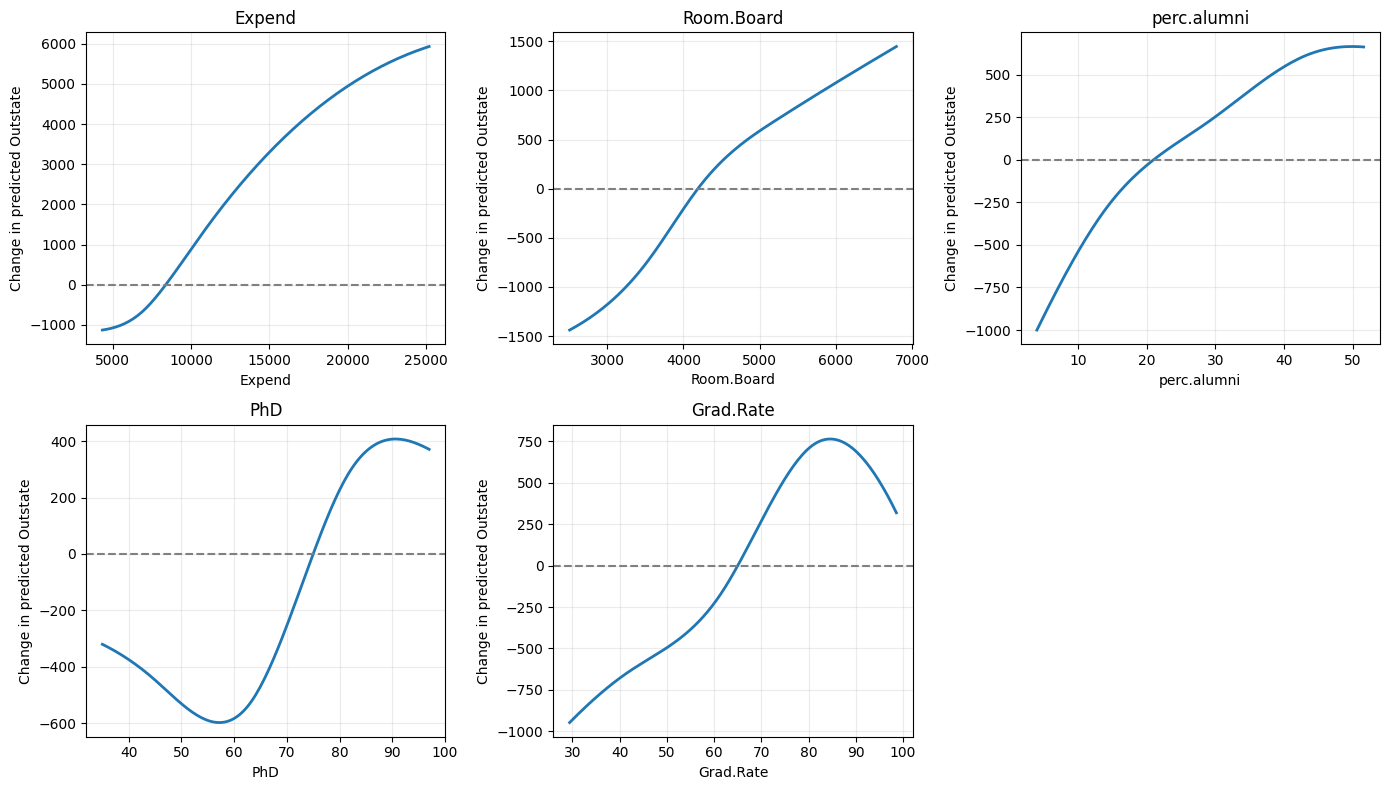

In [35]:
import statsmodels.formula.api as smf

# 1. 取得 Forward Selection 選出的變數
smooth_vars10 = [
    c for c in selected10
    if c != "Private_Yes"
]

linear_vars10 = [
    c for c in selected10
    if c == "Private_Yes"
]

# 2. 建立 GAM Formula
terms10 = [
    f'cr(Q("{c}"), df=4, constraints="center")'
    for c in smooth_vars10
]

terms10 += [
    f'Q("{c}")'
    for c in linear_vars10
]

formula10 = "Outstate ~ " + " + ".join(terms10)

# 3. 建立 Training Data
train_gam10 = X_train10[selected10].copy()
train_gam10["Outstate"] = y_train10

# 4. Fit GAM
gam_model10 = smf.ols(
    formula10,
    data=train_gam10
).fit()

# 5. 顯示模型結果
print(f"Training R²: {gam_model10.rsquared:.4f}")
print(f"Training MSE: {np.mean(gam_model10.resid**2):.2f}")

# 固定其他變數，觀察單一變數的影響
base10 = X_train10[selected10].median().to_dict()

for c in linear_vars10:
    base10[c] = float(X_train10[c].mode().iloc[0])

base_df10 = pd.DataFrame([base10])
base_pred10 = float(gam_model10.predict(base_df10).iloc[0])

ncols = 3
nrows = int(np.ceil(len(smooth_vars10) / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(14, 4 * nrows),
    squeeze=False
)

for ax, col in zip(axes.ravel(), smooth_vars10):

    grid = np.linspace(
        X_train10[col].quantile(0.02),
        X_train10[col].quantile(0.98),
        150
    )

    plot_df = pd.DataFrame([base10] * len(grid))
    plot_df[col] = grid

    # 相對於基準值的預測學費變化
    effect = (
        np.asarray(gam_model10.predict(plot_df))
        - base_pred10
    )

    ax.plot(grid, effect, linewidth=2)
    ax.axhline(0, color="gray", linestyle="--")

    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Change in predicted Outstate")
    ax.grid(alpha=0.25)

# 隱藏多餘的空白子圖
for ax in axes.ravel()[len(smooth_vars10):]:
    ax.axis("off")

fig.tight_layout()
plt.show()

### (c) 解答

使用 (a) 保留的 156 筆測試資料，評估 GAM 的預測表現，並與 Forward Selection 線性模型比較。

使用三項指標：

$$
MSE=\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2
$$

$$
RMSE=\sqrt{MSE}
$$

$$
R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}
$$

結果如下：

| Model | Test MSE | Test RMSE | Test $R^2$ |
|---|---:|---:|---:|
| Forward Selection | 3,868,925 | 1,966.96 | 0.7631 |
| **GAM** | **3,491,997** | **1,868.69** | **0.7862** |

可以看到 GAM 的 Test MSE 與 RMSE 均低於線性模型，且 Test $R^2$ 較高，表示 GAM 透過非線性函數改善了預測能力。在本次資料分割下，GAM 能解釋約 **78.62%** 的測試資料變異。

因為訓練集表現較好不代表預測能力一定較好，因此需要使用 Test Set 評估模型的泛化能力。

                 MSE       RMSE        MAE      R²
Linear  3.868925e+06  1966.9584  1546.8610  0.7631
GAM     3.446068e+06  1856.3588  1467.2689  0.7890


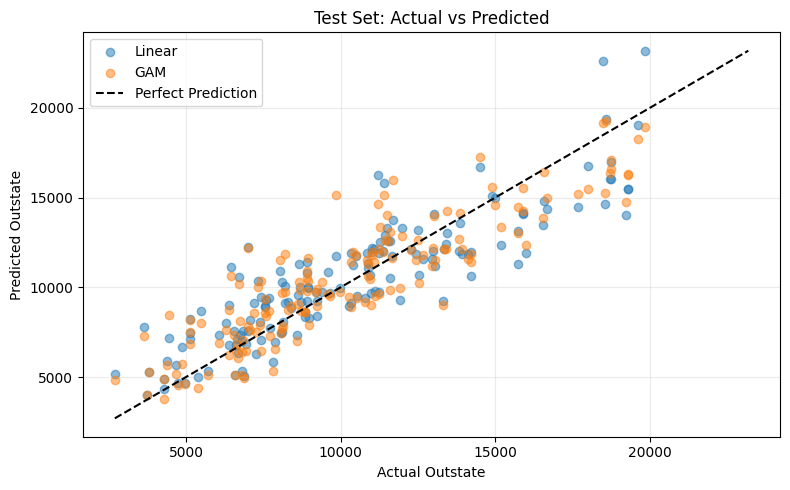

In [36]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. 使用 Test Set 預測
test_gam10 = X_test10[selected10].copy()

# GAM 預測
pred_gam10 = gam_model10.predict(test_gam10)

# Forward Selection 線性模型預測
pred_linear10 = final_model10.predict(
    sm.add_constant(test_gam10, has_constant="add")
)

# 2. 計算評估指標
def evaluate10(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)

    return {
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R²": r2_score(y_true, y_pred)
    }

results10c = pd.DataFrame({
    "Linear": evaluate10(y_test10, pred_linear10),
    "GAM": evaluate10(y_test10, pred_gam10)
}).T

print(results10c.round(4))

# 3. 繪製 Actual vs Predicted
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    y_test10,
    pred_linear10,
    alpha=0.5,
    label="Linear"
)

ax.scatter(
    y_test10,
    pred_gam10,
    alpha=0.5,
    label="GAM"
)

# 完美預測參考線
lo = min(y_test10.min(), pred_linear10.min(), pred_gam10.min())
hi = max(y_test10.max(), pred_linear10.max(), pred_gam10.max())

ax.plot(
    [lo, hi],
    [lo, hi],
    "k--",
    label="Perfect Prediction"
)

ax.set(
    xlabel="Actual Outstate",
    ylabel="Predicted Outstate",
    title="Test Set: Actual vs Predicted"
)

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### (d) 解答

使用 **Partial F-test** 比較線性模型與 Spline 模型，判斷各變數是否具有顯著的非線性關係。

$$
H_0:f_j(X_j)\text{ 為線性函數}
$$

$$
H_1:f_j(X_j)\text{ 存在非線性成分}
$$

設定顯著水準 $\alpha=0.05$，結果如下：

| Variable | F-statistic | p-value | Significant |
|---|---:|---:|---|
| Expend | 28.3149 | < 0.001 | Yes |
| Room.Board | 1.1860 | 0.3143 | No |
| perc.alumni | 0.8526 | 0.4655 | No |
| PhD | 2.0903 | 0.1003 | No |
| Grad.Rate | 2.4767 | 0.0604 | No |

可以看到只有 `Expend` 具有顯著的非線性關係（$p<0.05$）；`Grad.Rate` 接近顯著水準，但仍未達到 $0.05$。

如果拿來跟 (b) 小題透過眼睛目測所得出的結果有明顯不同，可以說明 GAM 曲線呈現彎曲不代表非線性效果一定顯著，仍需透過統計檢定確認。

In [37]:
from statsmodels.stats.anova import anova_lm

results10d = []

for target in smooth_vars10:

    # 將目標變數改成線性項，其餘保持 Spline
    terms = [
        f'Q("{v}")' if v == target
        else f'cr(Q("{v}"), df=4, constraints="center")'
        for v in smooth_vars10
    ]

    terms += [f'Q("{v}")' for v in linear_vars10]

    formula = "Outstate ~ " + " + ".join(terms)

    reduced_model = smf.ols(
        formula, data=train_gam10
    ).fit()

    # 比較線性與非線性模型
    test = anova_lm(reduced_model, gam_model10)

    results10d.append({
        "Variable": target,
        "F-statistic": test.iloc[1]["F"],
        "p-value": test.iloc[1]["Pr(>F)"]
    })

results10d = pd.DataFrame(results10d)

print(results10d.round(4))

      Variable  F-statistic  p-value
0       Expend      28.3149   0.0000
1   Room.Board       1.1860   0.3143
2  perc.alumni       0.8526   0.4655
3          PhD       2.0903   0.1003
4    Grad.Rate       2.4767   0.0604
